In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [23]:
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import MinMaxScaler

In [24]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/concrete_data.csv')
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [25]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [26]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [27]:
X = df.drop(columns=['Strength'])
y = df.iloc[:,-1]

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [29]:
scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = pd.DataFrame(X_train, columns=['Cement','Blast Furnace Slag','Fly Ash','Water','Superplasticizer','Coarse Aggregate','Fine Aggregate','Age'])
X_test = pd.DataFrame(X_test, columns=['Cement','Blast Furnace Slag','Fly Ash','Water','Superplasticizer','Coarse Aggregate','Fine Aggregate','Age'])

lr = LinearRegression()
lr.fit(X_train,y_train)

y_pred = lr.predict(X_test)

print('r2_score -> ',r2_score(y_test, y_pred))

r2_score ->  0.6275531792314848


In [30]:
lr = LinearRegression()

np.mean(cross_val_score(lr,X,y,scoring='r2',cv=10))

np.float64(0.2782072916087374)

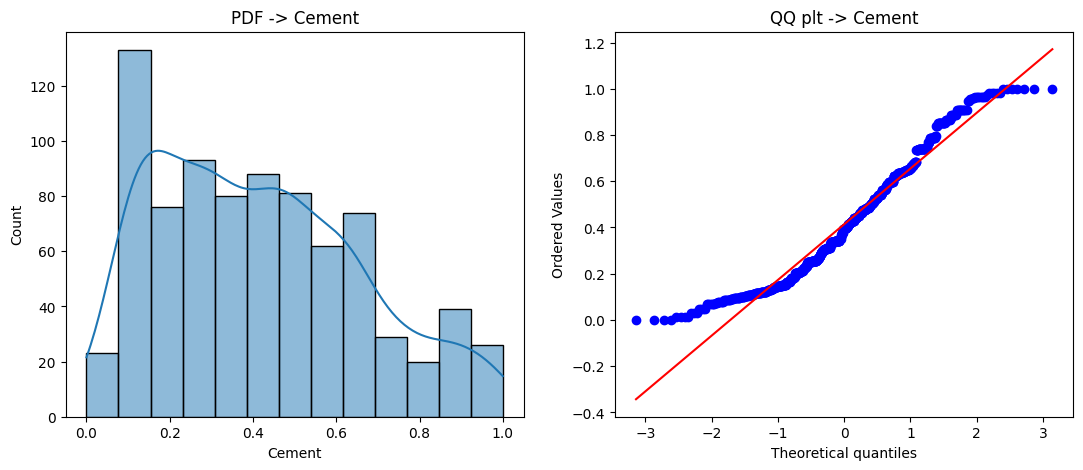

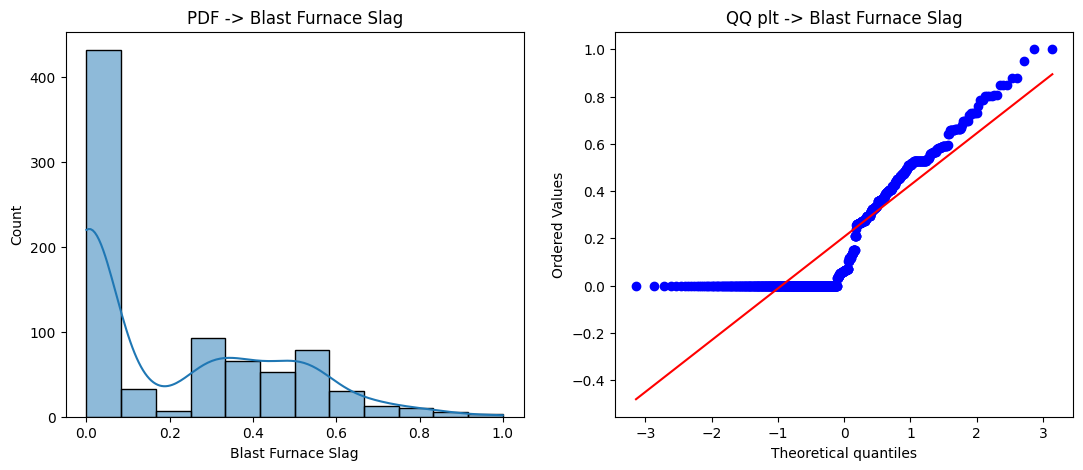

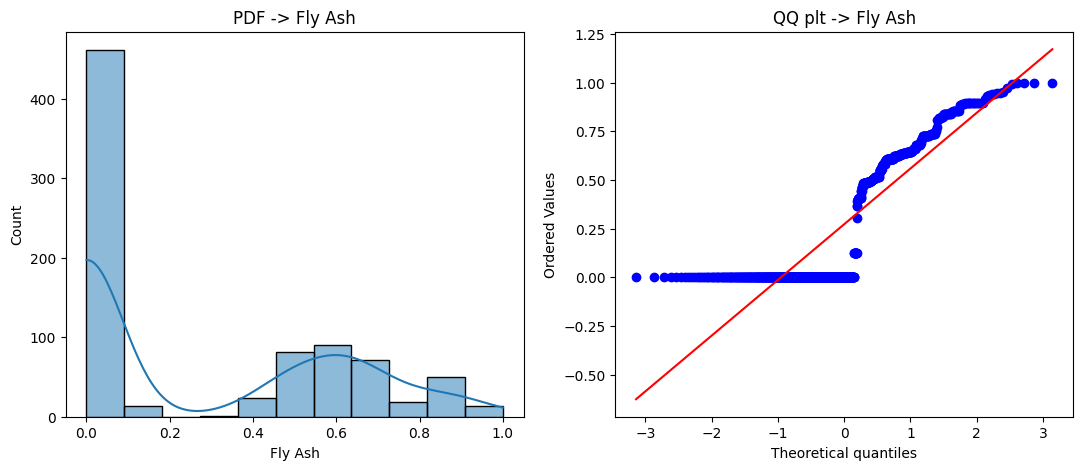

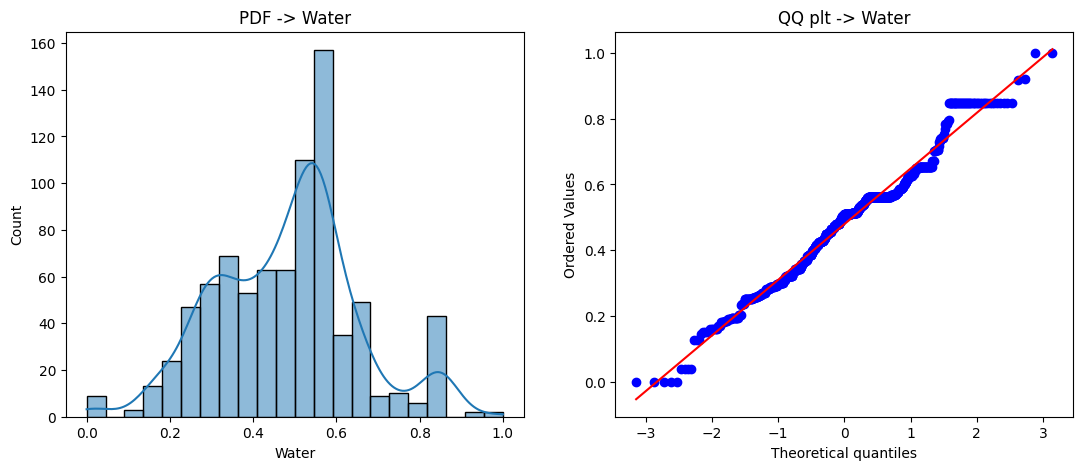

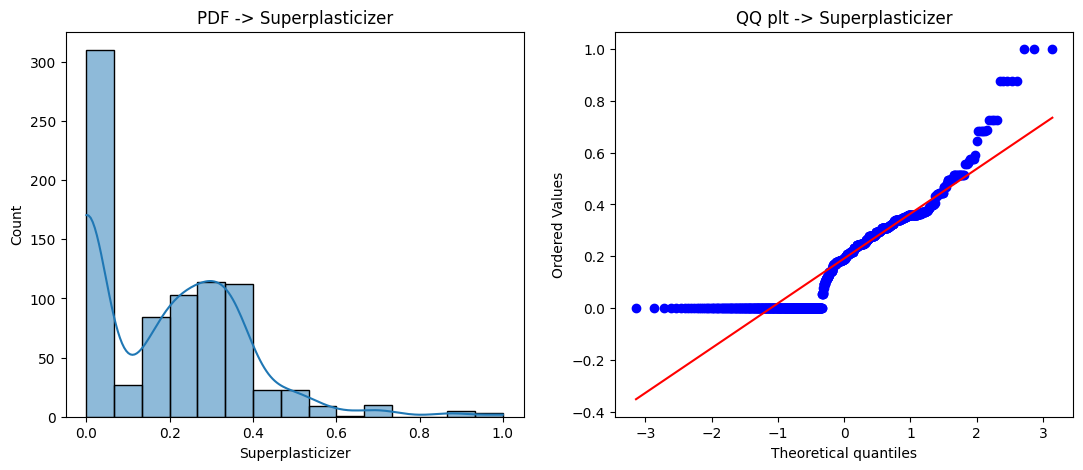

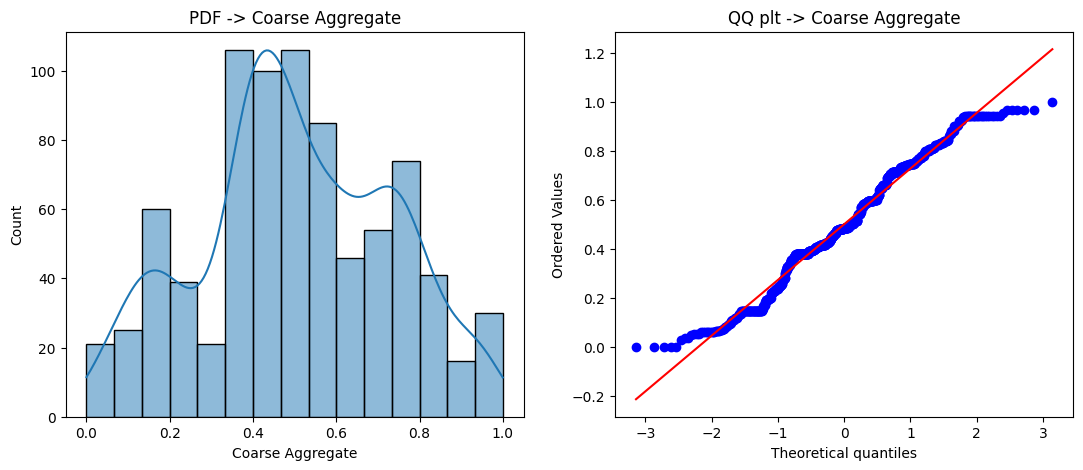

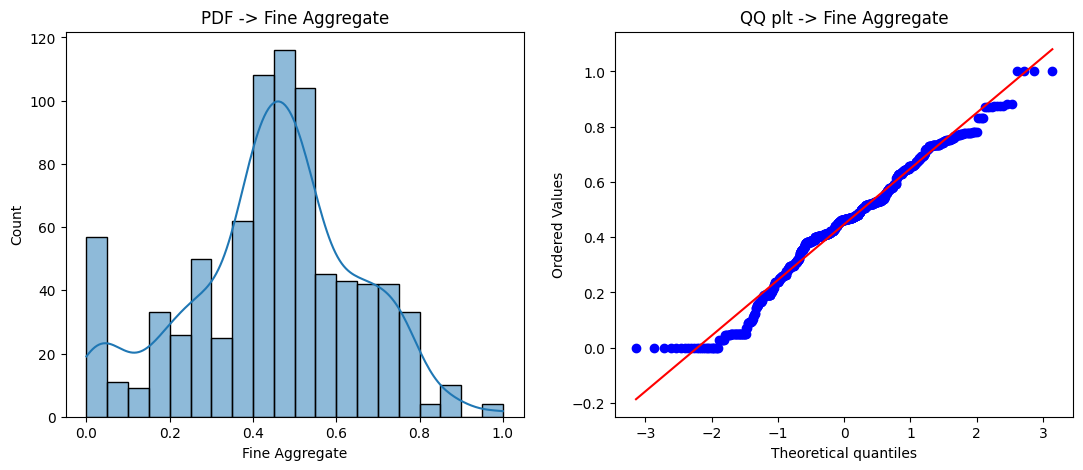

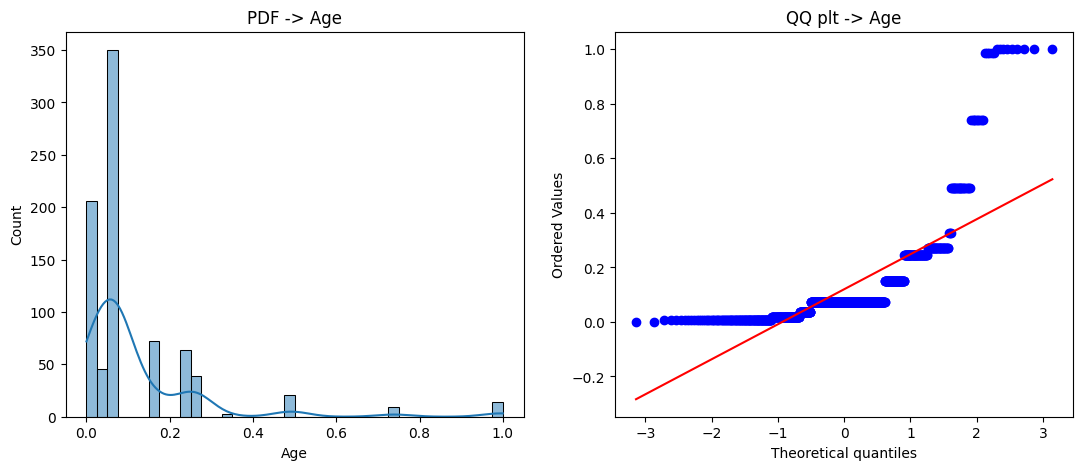

In [31]:
for col in X_train.columns:
    plt.figure(figsize=(13,5))

    plt.subplot(1,2,1)
    sns.histplot(X_train[col],kde=True)
    plt.title(f'PDF -> {col}')

    plt.subplot(1,2,2)
    stats.probplot(X_train[col], dist='norm', plot=plt)
    plt.title(f'QQ plt -> {col}')

    plt.show()

In [32]:
pt = PowerTransformer(method='box-cox')

X_train_transformed = pt.fit_transform(X_train+0.000001)
X_test_transformed = pt.transform(X_test+0.000001)
pd.DataFrame({'cols': X_train.columns,'box_cox_lambdas': pt.lambdas_ })

,cols,box_cox_lambdas
0,Cement,0.496054
1,Blast Furnace Slag,0.033003
2,Fly Ash,-0.054680
3,Water,0.815328
4,Superplasticizer,0.123332
5,Coarse Aggregate,0.803608
6,Fine Aggregate,0.712258
7,Age,0.165945


In [33]:
lr = LinearRegression()

lr.fit(X_train_transformed,y_train)

y_pred2 = lr.predict(X_test_transformed)

r2_score(y_test,y_pred2)

0.7939667759383426

In [34]:
lr = LinearRegression()
X_transformed = pt.fit_transform(X+0.000001)

print(np.mean(cross_val_score(lr,X_transformed,y,scoring='r2',cv=10)))

0.6466764736801414


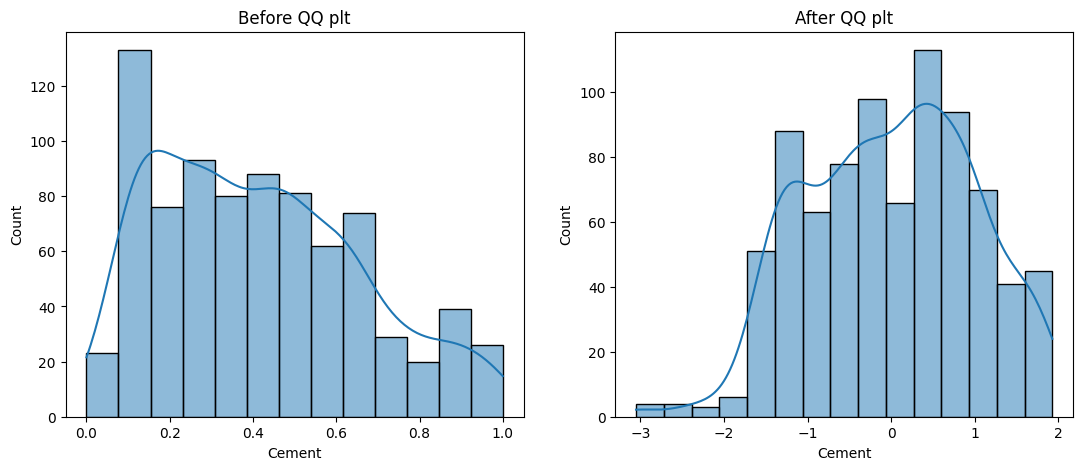

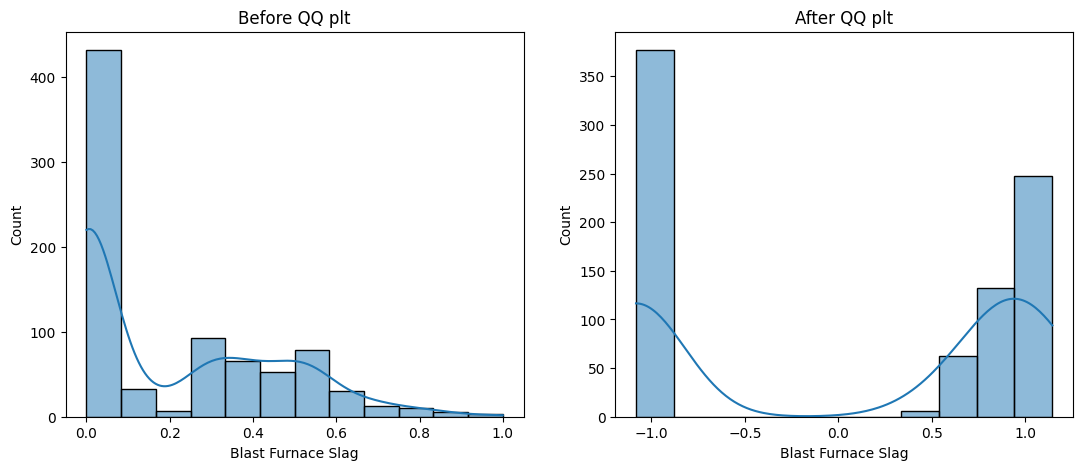

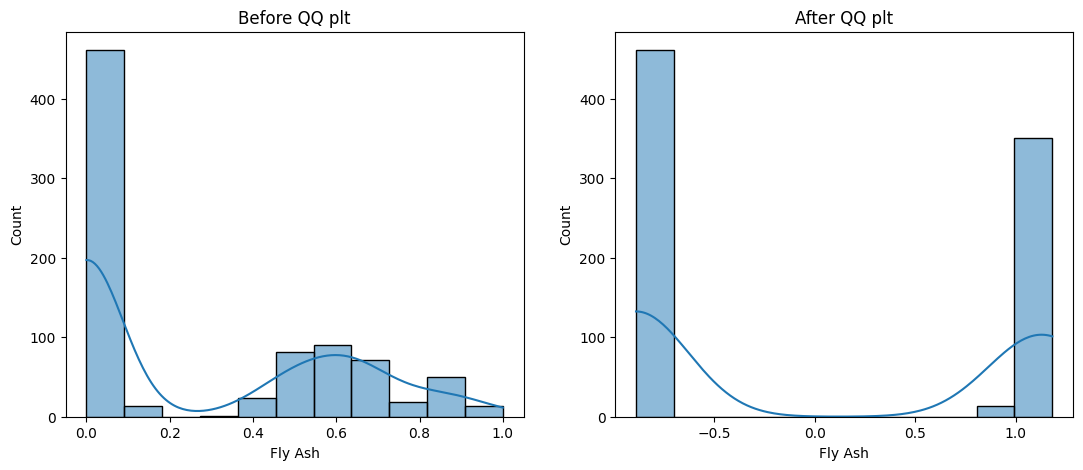

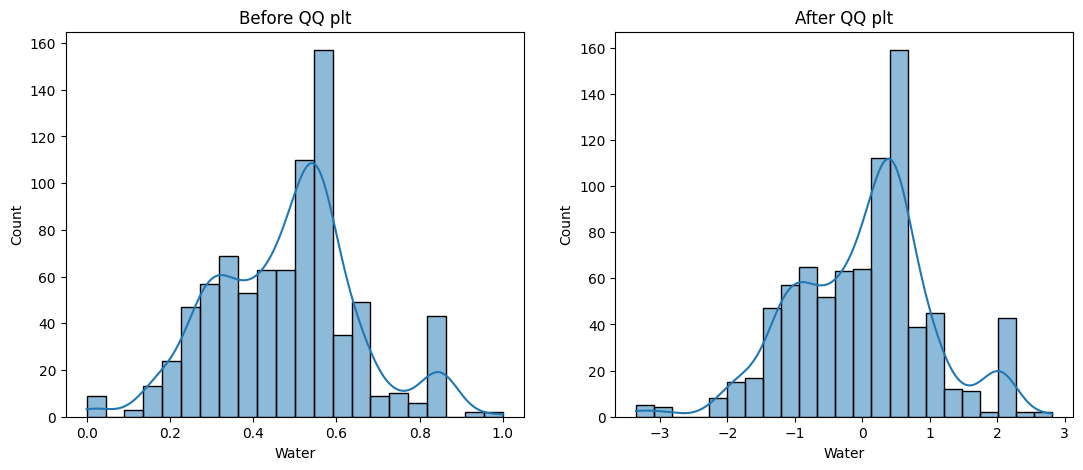

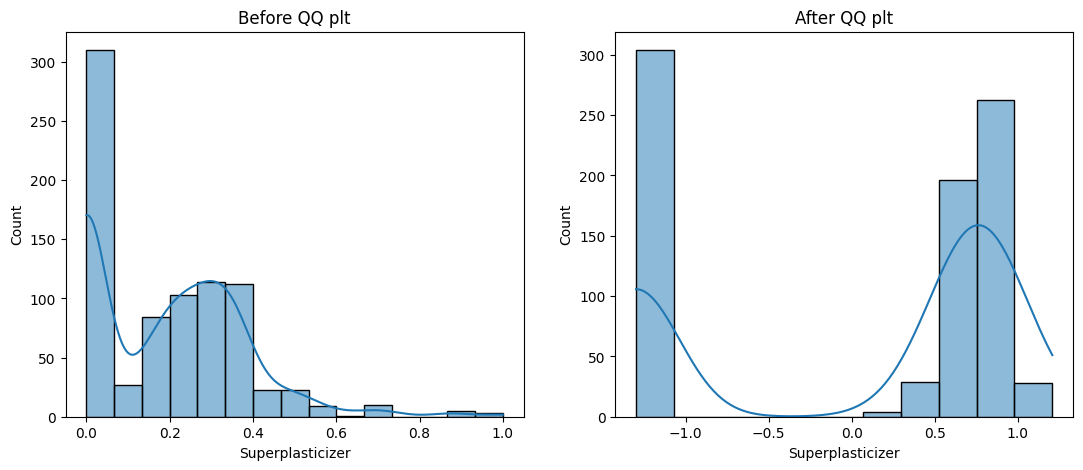

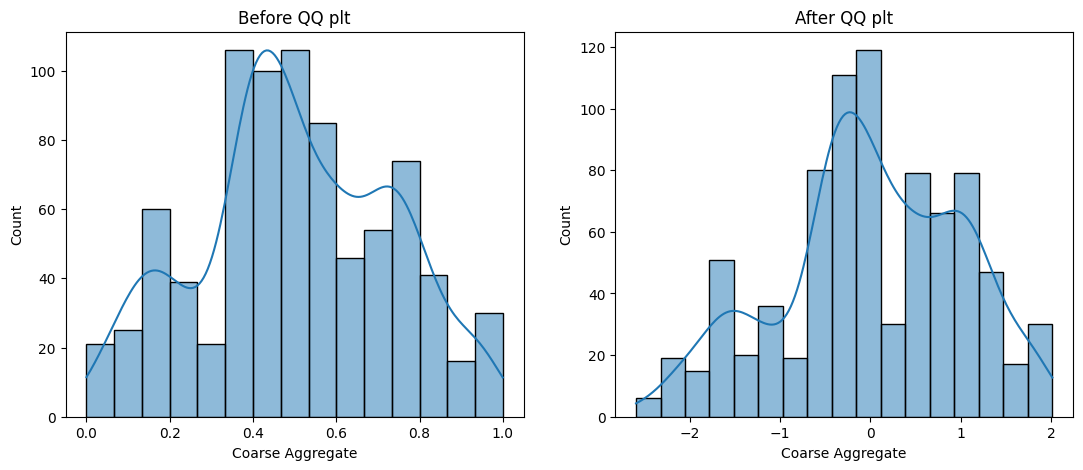

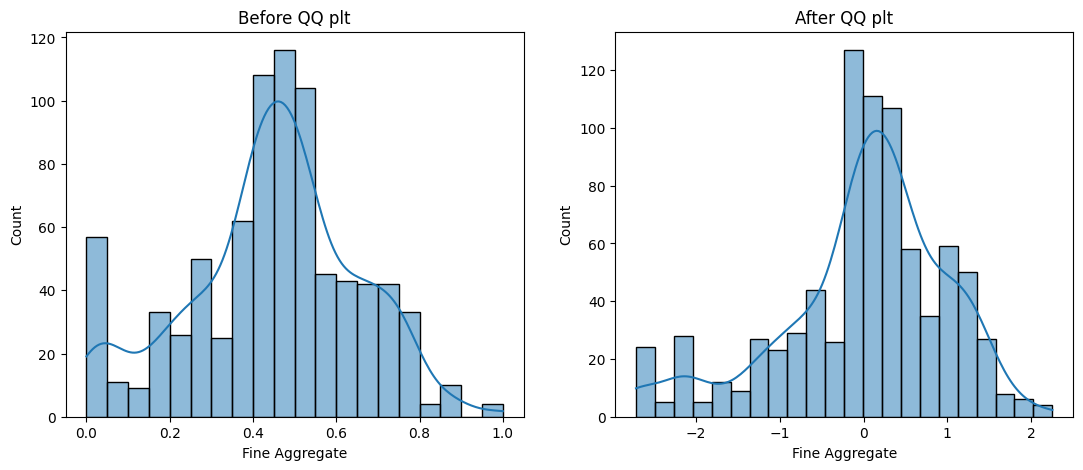

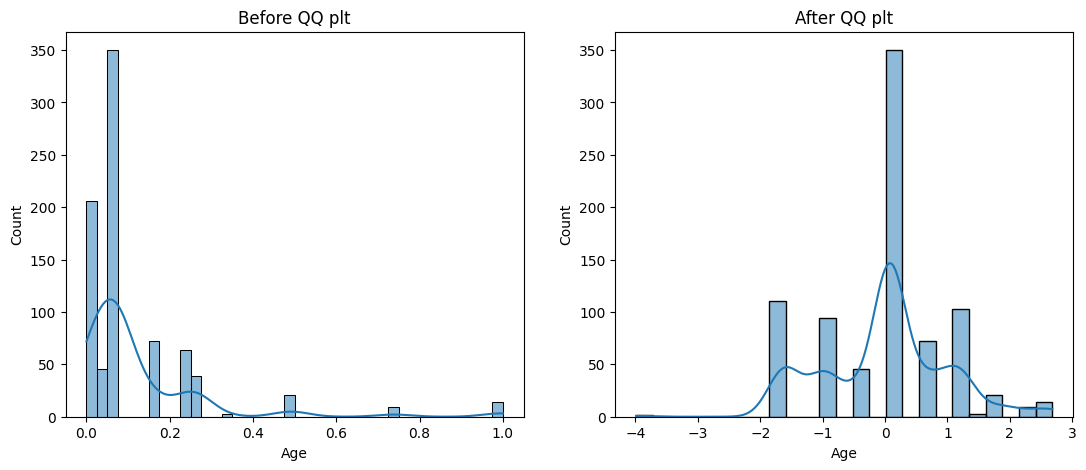

In [35]:
X_train_transformed = pd.DataFrame(X_train_transformed, columns=['Cement','Blast Furnace Slag','Fly Ash','Water','Superplasticizer','Coarse Aggregate','Fine Aggregate','Age'])

for col in X_train_transformed.columns:
    plt.figure(figsize=(13,5))

    plt.subplot(1,2,1)
    sns.histplot(X_train[col], kde=True)
    plt.title('Before QQ plt')

    plt.subplot(1,2,2)
    sns.histplot(X_train_transformed[col],kde=True)
    plt.title('After QQ plt')

    plt.show()

In [36]:
pt1 = PowerTransformer()

X_train_transformed1 = pt1.fit_transform(X_train)
X_test_transformed1 = pt1.transform(X_test)

lr1 = LinearRegression()

lr1.fit(X_train_transformed1,y_train)

y_pred3 = lr1.predict(X_test_transformed1)

print(r2_score(y_test,y_pred3))

pd.DataFrame({'cols':X_train.columns, 'yoe_Johnson_lambda':pt1.lambdas_})

0.8229496017958594


,cols,yoe_Johnson_lambda
0,Cement,-0.659497
1,Blast Furnace Slag,-2.718960
2,Fly Ash,-2.146507
3,Water,0.768008
4,Superplasticizer,-1.549738
5,Coarse Aggregate,1.020134
6,Fine Aggregate,1.568922
7,Age,-7.286351


In [37]:
pt = PowerTransformer()

X_transformed2 = pt.fit_transform(X)

lr2 = LinearRegression()

print(np.mean(cross_val_score(lr2,X_transformed2,y,scoring='r2',cv=10)))

0.6586548629094919


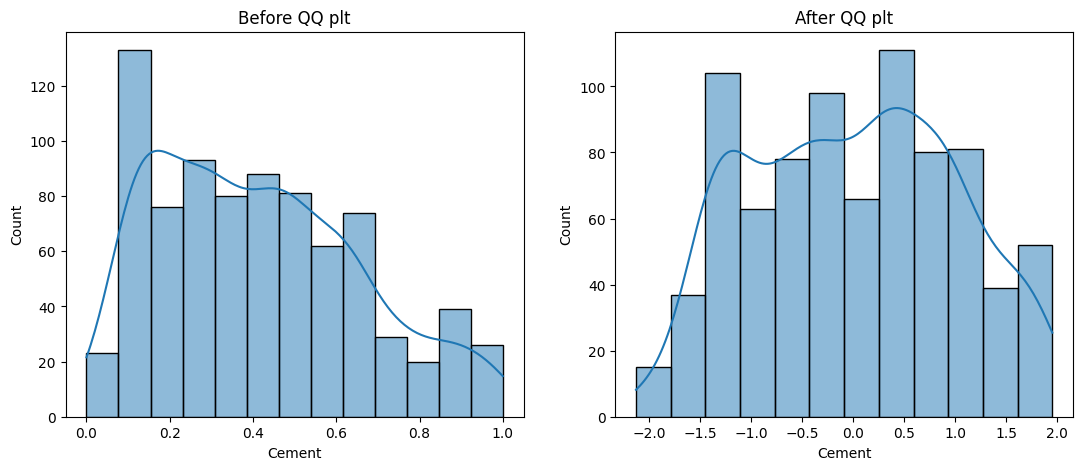

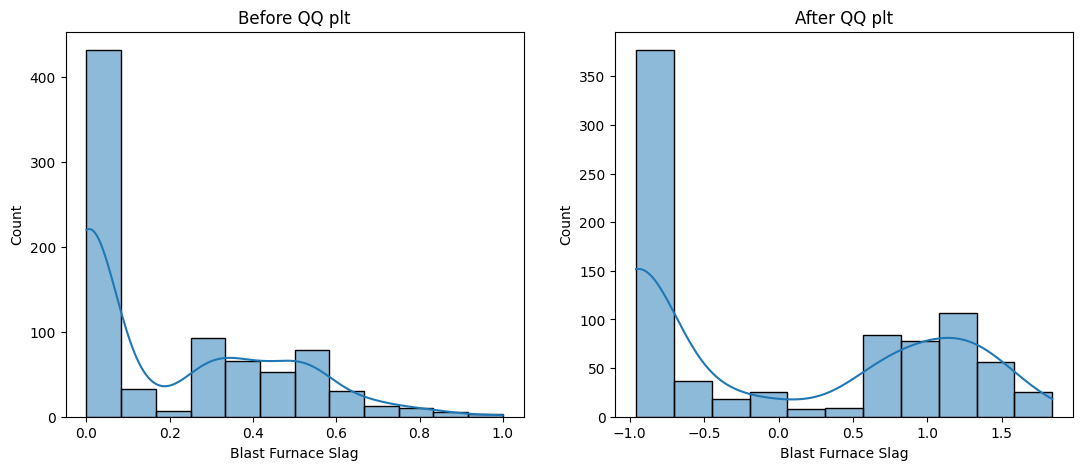

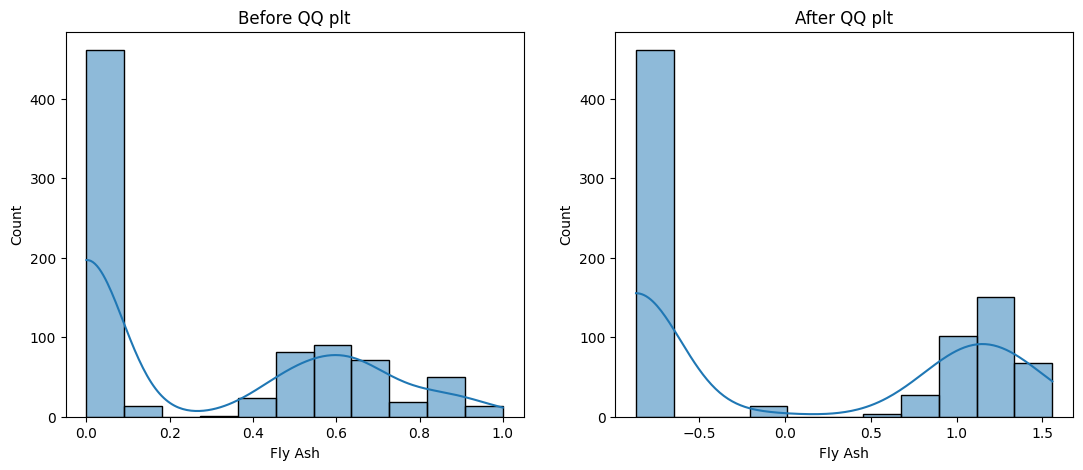

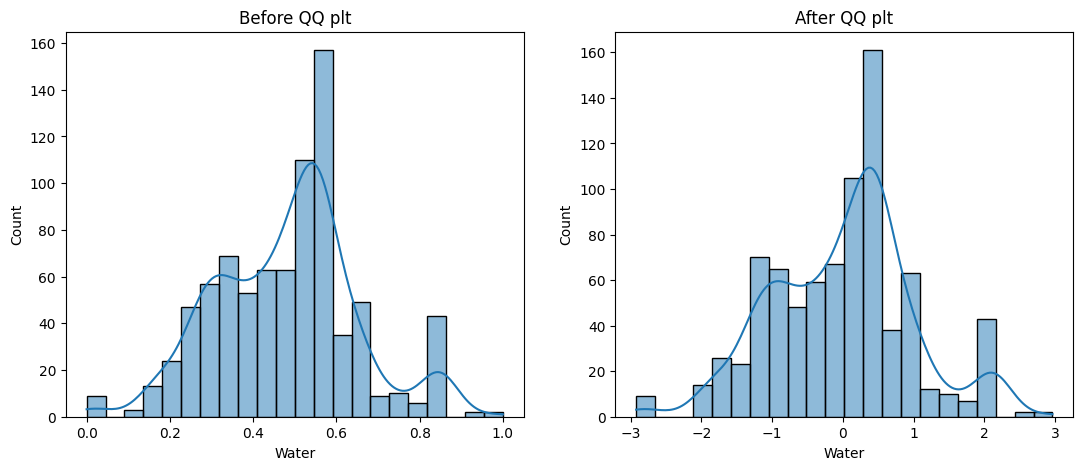

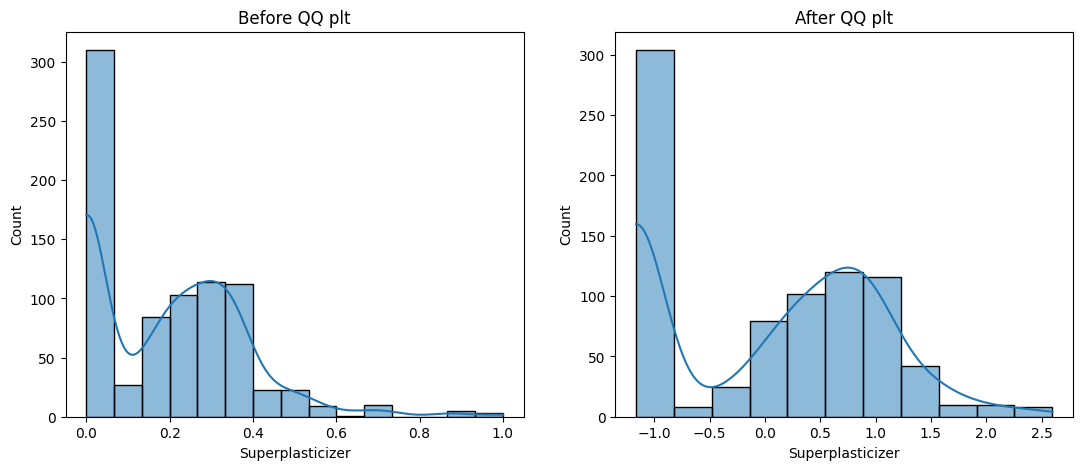

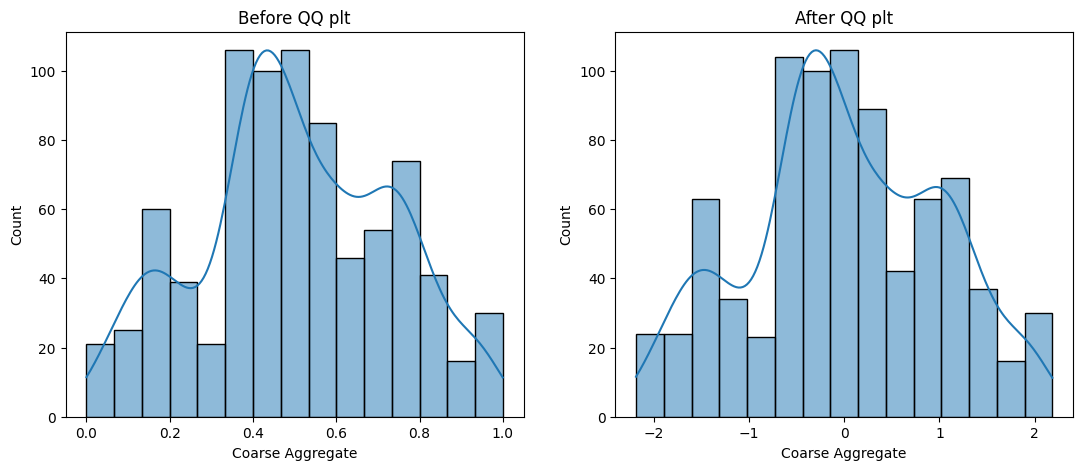

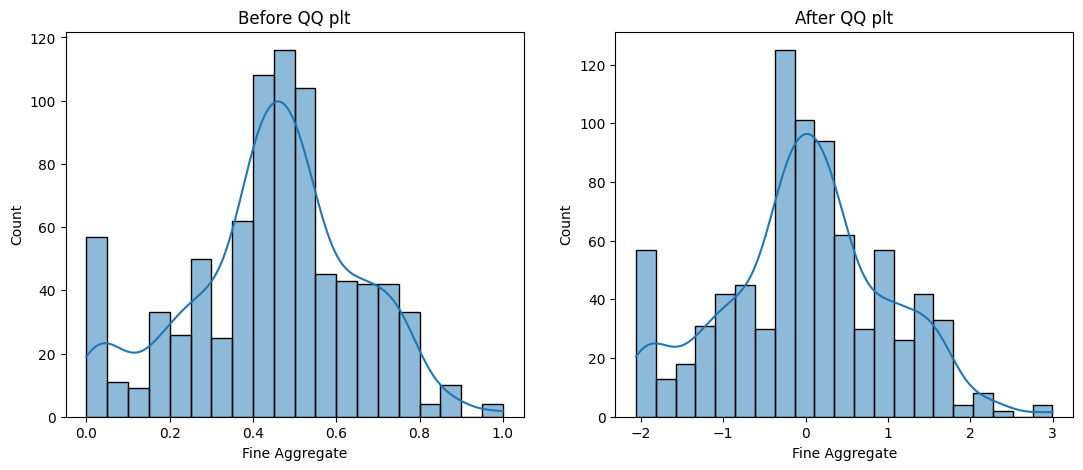

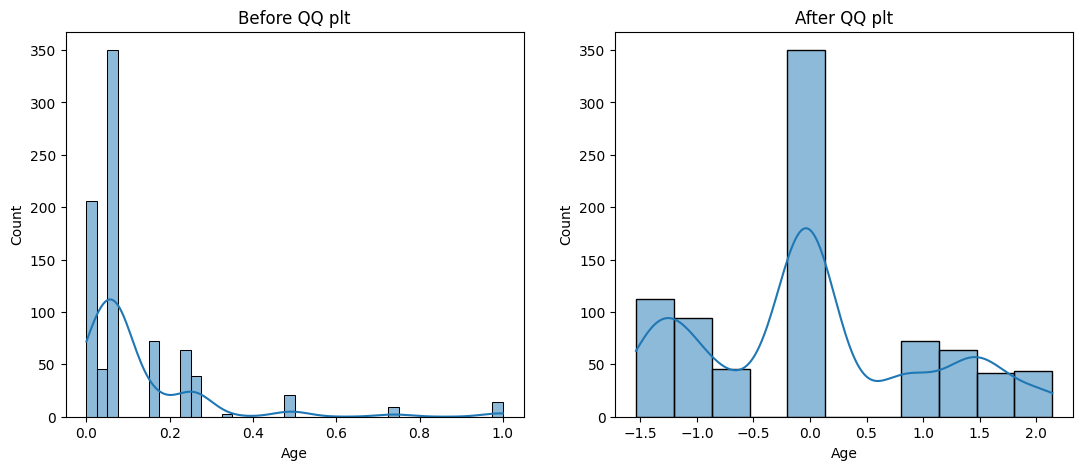

In [38]:
X_train_transformed1 = pd.DataFrame(X_train_transformed1, columns=X.columns)

for col in X_train_transformed1.columns:
    plt.figure(figsize=(13,5))

    plt.subplot(1,2,1)
    sns.histplot(X_train[col], kde=True)
    plt.title('Before QQ plt')

    plt.subplot(1,2,2)
    sns.histplot(X_train_transformed1[col],kde=True)
    plt.title('After QQ plt')

    plt.show()